In [1]:
# === CELL 1 (NB2) — Reload/Resume ===
from google.colab import drive
drive.mount('/content/drive')

import sys, os
DRIVE_ROOT = "/content/drive/MyDrive/FPX_Project"
sys.path.insert(0, os.path.join(DRIVE_ROOT, "utils"))
import checkpoint_utils as cu

config = cu.load_json("config", "project_config")
print("=== CELL 1 (NB2) === Resumed FPX project.")
print(f"Dataset: {config.get('dataset')} | Clients: {config.get('num_clients')} | Rounds: {config.get('num_rounds')}")
cu.project_status()

Mounted at /content/drive
=== CELL 1 (NB2) === Resumed FPX project.
Dataset: breast_cancer_sklearn | Clients: 8 | Rounds: 20
=== FPX Project Drive Status ===
config: 1 file(s)
   - project_config.json
data: 0 file(s)
checkpoints/fl_sim: 0 file(s)
checkpoints/signals: 0 file(s)
checkpoints/interface: 0 file(s)
checkpoints/eval: 0 file(s)
outputs: 0 file(s)
logs: 1 file(s)
   - project_log.txt


In [2]:
# === CELL 2 (NB2) — Dependencies ===
import numpy as np
import torch
import torch.nn as nn
import copy
from sklearn.datasets import load_breast_cancer
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

print("=== CELL 2 (NB2) === torch:", torch.__version__, "| CUDA available:", torch.cuda.is_available())

=== CELL 2 (NB2) === torch: 2.11.0+cpu | CUDA available: False


In [3]:
# === CELL 3 (NB2) — Load + preprocess data ===
existing = cu.load_pickle("data", "data_split")

if existing is not None:
    X_train, X_test, y_train, y_test = existing["X_train"], existing["X_test"], existing["y_train"], existing["y_test"]
    print("=== CELL 3 (NB2) === Loaded existing data split from Drive.")
else:
    data = load_breast_cancer()
    X, y = data.data, data.target
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42, stratify=y
    )
    scaler = StandardScaler().fit(X_train)
    X_train, X_test = scaler.transform(X_train), scaler.transform(X_test)
    cu.save_pickle(
        {"X_train": X_train, "X_test": X_test, "y_train": y_train, "y_test": y_test},
        "data", "data_split"
    )
    print("=== CELL 3 (NB2) === New data split created and saved to Drive.")

print(f"Train: {X_train.shape}, Test: {X_test.shape}")

[2026-09-02 10:14:58] Saved pickle checkpoint: data/data_split.pkl
=== CELL 3 (NB2) === New data split created and saved to Drive.
Train: (455, 30), Test: (114, 30)


In [4]:
# === CELL 4 (NB2) — Non-IID client partition ===
def dirichlet_partition(y, num_clients, alpha, seed=42, min_size=15):
    rng = np.random.default_rng(seed)
    num_classes = len(np.unique(y))
    for attempt in range(50):
        class_idx = [np.where(y == c)[0].copy() for c in range(num_classes)]
        client_idx = [[] for _ in range(num_clients)]
        for c in range(num_classes):
            idx_c = class_idx[c]
            rng.shuffle(idx_c)
            proportions = rng.dirichlet(alpha=[alpha] * num_clients)
            splits = (np.cumsum(proportions) * len(idx_c)).astype(int)[:-1]
            parts = np.split(idx_c, splits)
            for i, p in enumerate(parts):
                client_idx[i].extend(p.tolist())
        sizes = [len(x) for x in client_idx]
        if min(sizes) >= min_size:
            return [np.array(idx) for idx in client_idx]
        seed += 1
    raise RuntimeError("Could not satisfy min_size after 50 attempts — lower min_size or raise alpha")

existing_partition = cu.load_pickle("data", "client_partition")

if existing_partition is not None:
    client_indices = existing_partition
    print("=== CELL 4 (NB2) === Loaded existing client partition from Drive.")
else:
    client_indices = dirichlet_partition(
        y_train, num_clients=config["num_clients"], alpha=config["non_iid_alpha"], min_size=15
    )
    cu.save_pickle(client_indices, "data", "client_partition")
    print("=== CELL 4 (NB2) === New client partition created and saved to Drive.")

for i, idx in enumerate(client_indices):
    classes, counts = np.unique(y_train[idx], return_counts=True)
    print(f"Client {i}: n={len(idx)}, class dist={dict(zip(classes.tolist(), counts.tolist()))}")

[2026-09-02 10:15:04] Saved pickle checkpoint: data/client_partition.pkl
=== CELL 4 (NB2) === New client partition created and saved to Drive.
Client 0: n=16, class dist={0: 12, 1: 4}
Client 1: n=62, class dist={1: 62}
Client 2: n=47, class dist={0: 44, 1: 3}
Client 3: n=93, class dist={0: 89, 1: 4}
Client 4: n=48, class dist={0: 4, 1: 44}
Client 5: n=60, class dist={0: 16, 1: 44}
Client 6: n=66, class dist={0: 3, 1: 63}
Client 7: n=63, class dist={0: 2, 1: 61}


In [5]:
# === CELL 5 (NB2) — Model definition + helpers ===
class SmallMLP(nn.Module):
    def __init__(self, in_dim):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_dim, 32), nn.ReLU(),
            nn.Linear(32, 16), nn.ReLU(),
            nn.Linear(16, 2)
        )
    def forward(self, x):
        return self.net(x)

def flat_params(state_dict):
    return torch.cat([v.float().view(-1) for v in state_dict.values()])

def local_train(global_state, X_c, y_c, in_dim, epochs=5, lr=0.05):
    model = SmallMLP(in_dim)
    model.load_state_dict(global_state)
    opt = torch.optim.SGD(model.parameters(), lr=lr)
    loss_fn = nn.CrossEntropyLoss()
    Xt = torch.tensor(X_c, dtype=torch.float32)
    yt = torch.tensor(y_c, dtype=torch.long)
    model.train()
    for _ in range(epochs):
        opt.zero_grad()
        out = model(Xt)
        loss = loss_fn(out, yt)
        loss.backward()
        opt.step()
    return model.state_dict(), loss.item(), len(y_c)

def fedavg(states, weights):
    total = sum(weights)
    avg_state = copy.deepcopy(states[0])
    for key in avg_state:
        avg_state[key] = sum(states[i][key].float() * (weights[i] / total) for i in range(len(states)))
    return avg_state

print("=== CELL 5 (NB2) === Model + helpers defined.")

=== CELL 5 (NB2) === Model + helpers defined.


In [6]:
# === CELL 6 (NB2) — FL training loop with per-round checkpointing ===
in_dim = X_train.shape[1]
NUM_ROUNDS = config["num_rounds"]

resume_state = cu.load_pickle("checkpoints/fl_sim", "latest_round_state")

if resume_state is not None:
    global_model = SmallMLP(in_dim)
    global_model.load_state_dict(resume_state["global_state"])
    history = resume_state["history"]
    start_round = resume_state["round"] + 1
    print(f"=== CELL 6 (NB2) === Resuming training from round {start_round}")
else:
    global_model = SmallMLP(in_dim)
    history = []
    start_round = 1
    print("=== CELL 6 (NB2) === Starting fresh training run")

for rnd in range(start_round, NUM_ROUNDS + 1):
    global_state_before = copy.deepcopy(global_model.state_dict())
    global_flat_before = flat_params(global_state_before)

    client_states, client_losses, client_weights = [], [], []
    for i, idx in enumerate(client_indices):
        Xc, yc = X_train[idx], y_train[idx]
        state, loss, n = local_train(global_state_before, Xc, yc, in_dim)
        client_states.append(state)
        client_losses.append(loss)
        client_weights.append(n)

    new_global_state = fedavg(client_states, client_weights)
    global_model.load_state_dict(new_global_state)
    new_global_flat = flat_params(new_global_state)

    global_model.eval()
    with torch.no_grad():
        preds = global_model(torch.tensor(X_test, dtype=torch.float32)).argmax(dim=1).numpy()
    acc = (preds == y_test).mean()

    aggregated_delta = new_global_flat - global_flat_before
    round_client_records = []
    for i, state in enumerate(client_states):
        client_delta = flat_params(state) - global_flat_before
        cos_sim = torch.nn.functional.cosine_similarity(
            aggregated_delta.unsqueeze(0), client_delta.unsqueeze(0)
        ).item()
        round_client_records.append({
            "client_id": i, "loss": client_losses[i], "n_samples": client_weights[i],
            "update_norm": client_delta.norm().item(), "cos_sim_to_aggregate": cos_sim
        })

    history.append({"round": rnd, "test_accuracy": float(acc), "clients": round_client_records})

    cu.save_pickle(
        {"global_state": new_global_state, "history": history, "round": rnd},
        "checkpoints/fl_sim", "latest_round_state"
    )
    cu.save_pickle(
        {"global_state": new_global_state, "history": history, "round": rnd},
        "checkpoints/fl_sim", f"round_{rnd:03d}"
    )

    print(f"=== CELL 6 (NB2) === Round {rnd}/{NUM_ROUNDS} | acc={acc:.4f} | checkpoint saved")

print("=== CELL 6 (NB2) === Training complete.")

=== CELL 6 (NB2) === Starting fresh training run
[2026-09-02 10:15:20] Saved pickle checkpoint: checkpoints/fl_sim/latest_round_state.pkl
[2026-09-02 10:15:20] Saved pickle checkpoint: checkpoints/fl_sim/round_001.pkl
=== CELL 6 (NB2) === Round 1/20 | acc=0.7456 | checkpoint saved
[2026-09-02 10:15:20] Saved pickle checkpoint: checkpoints/fl_sim/latest_round_state.pkl
[2026-09-02 10:15:20] Saved pickle checkpoint: checkpoints/fl_sim/round_002.pkl
=== CELL 6 (NB2) === Round 2/20 | acc=0.7895 | checkpoint saved
[2026-09-02 10:15:20] Saved pickle checkpoint: checkpoints/fl_sim/latest_round_state.pkl
[2026-09-02 10:15:20] Saved pickle checkpoint: checkpoints/fl_sim/round_003.pkl
=== CELL 6 (NB2) === Round 3/20 | acc=0.8333 | checkpoint saved
[2026-09-02 10:15:20] Saved pickle checkpoint: checkpoints/fl_sim/latest_round_state.pkl
[2026-09-02 10:15:20] Saved pickle checkpoint: checkpoints/fl_sim/round_004.pkl
=== CELL 6 (NB2) === Round 4/20 | acc=0.8772 | checkpoint saved
[2026-09-02 10:15:2

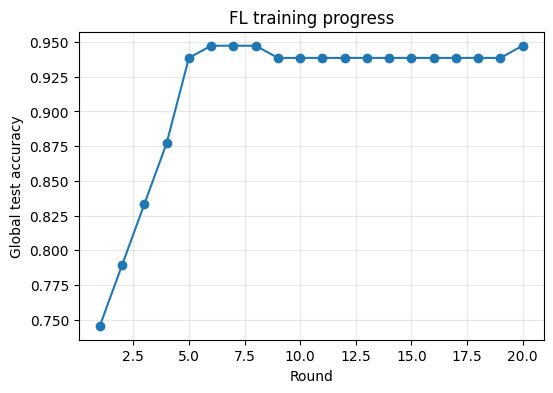

[2026-09-02 10:15:25] Saved JSON checkpoint: config/project_config.json
[2026-09-02 10:15:25] Saved JSON checkpoint: outputs/p2_summary.json
=== CELL 7 (NB2) === Final accuracy after 20 rounds: 0.9474
Plot saved to Drive: outputs/fl_training_curve.png


In [7]:
# === CELL 7 (NB2) — Final summary + plot [FIXED] ===
import matplotlib.pyplot as plt

os.makedirs(os.path.join(DRIVE_ROOT, "outputs"), exist_ok=True)  # <-- fix: ensure dir exists before raw file write

accs = [h["test_accuracy"] for h in history]
plt.figure(figsize=(6, 4))
plt.plot(range(1, len(accs) + 1), accs, marker="o")
plt.xlabel("Round")
plt.ylabel("Global test accuracy")
plt.title("FL training progress")
plt.grid(alpha=0.3)
plt.savefig(os.path.join(DRIVE_ROOT, "outputs", "fl_training_curve.png"), dpi=120, bbox_inches="tight")
plt.show()

config["current_phase"] = "P2_complete"
cu.save_json(config, "config", "project_config")
cu.save_json({"final_round": len(history), "final_accuracy": accs[-1]}, "outputs", "p2_summary")

print(f"=== CELL 7 (NB2) === Final accuracy after {len(history)} rounds: {accs[-1]:.4f}")
print("Plot saved to Drive: outputs/fl_training_curve.png")